# Airbnb Strategy Lab - Analyse exploratoire
**Contexte : ** un fonds d'investissement veut repérer les logements Airbnb sous-évalués à New York. 

**Données :** AB_NYC_2019 (kaggle), 48 895 annonces. 

In [108]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("../data/AB_NYC_2019.csv")
df.shape


(48895, 16)

## 1. Chargement des données
On importe les bibliothèques nécessaire puis on charge le fichier CSV. 

## Aperçu des premières lignes
On affiche les 5 premières lignes pour voir à quoi ressemblent les données.

In [109]:
df.head()

,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
0,2539,Clean & quiet apt home by the park,2787,John,Brooklyn,Kensington,40.64749,-73.97237,Private room,149,1,9,2018-10-19,0.21,6,365
1,2595,Skylit Midtown Castle,2845,Jennifer,Manhattan,Midtown,40.75362,-73.98377,Entire home/apt,225,1,45,2019-05-21,0.38,2,355
2,3647,THE VILLAGE OF HARLEM....NEW YORK !,4632,Elisabeth,Manhattan,Harlem,40.80902,-73.94190,Private room,150,3,0,NaN,NaN,1,365
3,3831,Cozy Entire Floor of Brownstone,4869,LisaRoxanne,Brooklyn,Clinton Hill,40.68514,-73.95976,Entire home/apt,89,1,270,2019-07-05,4.64,1,194
4,5022,Entire Apt: Spacious Studio/Loft by central park,7192,Laura,Manhattan,East Harlem,40.79851,-73.94399,Entire home/apt,80,10,9,2018-11-19,0.10,1,0


## Structure du dataset
On regarde le type de chaque colonne et le nombre de cases remplies

In [110]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48895 entries, 0 to 48894
Data columns (total 16 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   id                              48895 non-null  int64  
 1   name                            48879 non-null  object 
 2   host_id                         48895 non-null  int64  
 3   host_name                       48874 non-null  object 
 4   neighbourhood_group             48895 non-null  object 
 5   neighbourhood                   48895 non-null  object 
 6   latitude                        48895 non-null  float64
 7   longitude                       48895 non-null  float64
 8   room_type                       48895 non-null  object 
 9   price                           48895 non-null  int64  
 10  minimum_nights                  48895 non-null  int64  
 11  number_of_reviews               48895 non-null  int64  
 12  last_review                     

**OBSERVATION :**
- Le dataset contient 48 895 annonces et 16 colonnes. 
- `name` (16) et `host name` (21) ont quelques valeurs manquantes, en nombre négligeable. 
- `last_review` et `review_per_month` ont chacune 10 052 valeurs manquantes : ce sont les logements qui n'ont jamais reçu d'avis (`number_of_review = 0`). 
-`last_review` est stockée en texte (`object`) alors que c'est une date. 
- `price` est déjà numérique ('int64')

## Statistiques descriptives
On regarde la moyenne, le minimum, le maximum et la médiane des colonnes numériques. 

In [111]:
df.describe()


,id,host_id,latitude,longitude,price,minimum_nights,number_of_reviews,reviews_per_month,calculated_host_listings_count,availability_365
count,4.889500e+04,4.889500e+04,48895.000000,48895.000000,48895.000000,48895.000000,48895.000000,38843.000000,48895.000000,48895.000000
mean,1.901714e+07,6.762001e+07,40.728949,-73.952170,152.720687,7.029962,23.274466,1.373221,7.143982,112.781327
std,1.098311e+07,7.861097e+07,0.054530,0.046157,240.154170,20.510550,44.550582,1.680442,32.952519,131.622289
min,2.539000e+03,2.438000e+03,40.499790,-74.244420,0.000000,1.000000,0.000000,0.010000,1.000000,0.000000
25%,9.471945e+06,7.822033e+06,40.690100,-73.983070,69.000000,1.000000,1.000000,0.190000,1.000000,0.000000
50%,1.967728e+07,3.079382e+07,40.723070,-73.955680,106.000000,3.000000,5.000000,0.720000,1.000000,45.000000
75%,2.915218e+07,1.074344e+08,40.763115,-73.936275,175.000000,5.000000,24.000000,2.020000,2.000000,227.000000
max,3.648724e+07,2.743213e+08,40.913060,-73.712990,10000.000000,1250.000000,629.000000,58.500000,327.000000,365.000000


**Observation :**
- **price** : la médiane est de 106$ mais la moyenne est de 152$
Quelques logements très chers (jusqu'à 10 000$) tirent la moyenne vers le haut. 
- Certains prix valent **0 $** : c'est impossible, ce sont des erreurs à supprimer. 
- **minimum_night** monte jusqu'à 1250 nuits (plus de 3 ans), ce qui est illogique pour de la location courte durée. 
- Ces valeurs aberrantes seront traitées lors du nettoyage. 

## Valeurs manquantes
On compte les cases vides de chaque colonne, en nombre et en pourcentage. 

In [112]:
manquants = df.isnull().sum()
pourcentage = (manquants / len(df) * 100).round(2)

tableau_manquants = pd.DataFrame({
    "nb_manquants": manquants,
    "pourcentage": pourcentage
})
tableau_manquants

,nb_manquants,pourcentage
id,0,0.00
name,16,0.03
host_id,0,0.00
host_name,21,0.04
neighbourhood_group,0,0.00
neighbourhood,0,0.00
latitude,0,0.00
longitude,0,0.00
room_type,0,0.00
price,0,0.00


**Observation :**
- 'name' (0,03%) et 'host_name' (0,04%) : très peu de valeurs manquantes, sans impact sur l'analyse. 
- 'last_review' et 'review_per_month' : 20,56% de valeurs manquantes qui corresponds aux logements sans aucun avis. 
- Toutes les autres colonnes sont complète, y compris 'price' 

## 2. Nettoyage des données

### Traitement des valeurs manquantes
On travaille sur une copie ('df_clean') pour garder les données d'origine intactes. 

**Stratégie :**

-`reviews_per_month` : on remplace les vides par **0**, car un logement sans avis a logiquement 0 avis par mois. 
- `name` et `host_name` : on remplace par **Inconnu**. Ces colonnes ne servent pas à l'analyse et on ne veut pas perdre ces logements. 
- `last_review` : on la convertit en **date**. Les vides restent vides (« NaT » = pas de date), car on ne peut pas inventer une date d'avis.  

In [113]:
df_clean = df.copy()

df_clean["reviews_per_month"] = df_clean["reviews_per_month"].fillna(0)
df_clean["name"] = df_clean["name"].fillna("Inconnu")
df_clean["host_name"] = df_clean["host_name"].fillna("Inconnu")
df_clean["last_review"] = pd.to_datetime(df_clean["last_review"])

df_clean.isnull().sum()

id                                    0
name                                  0
host_id                               0
host_name                             0
neighbourhood_group                   0
neighbourhood                         0
latitude                              0
longitude                             0
room_type                             0
price                                 0
minimum_nights                        0
number_of_reviews                     0
last_review                       10052
reviews_per_month                     0
calculated_host_listings_count        0
availability_365                      0
dtype: int64

### Suppresion des valeurs aberrantes

- **Prix à 0$** : impossible, ce sont des erreurs de saisies. 
- **Prix extrèmes** : on garde les logements sous le 99e percentile (799$). Le 1% correspond à des cas exceptionnels qui fausseraient l'analyse et le modèle. 
- **minimum_night > 30** : au delà de 30 nuits, ce n'est plus de la location de courte durée (seuil légal à New York).  

In [114]:
seuil_prix = df_clean["price"].quantile(0.99)
print("Seuil du 99e percentile :", seuil_prix)

avant = len(df_clean)

df_clean = df_clean[df_clean["price"] > 0]
df_clean = df_clean[df_clean["price"] <= seuil_prix]
df_clean = df_clean[df_clean["minimum_nights"] <= 30]

apres = len(df_clean)
print("Lignes avant :", avant)
print("Lignes après :", apres)
print("Lignes supprimées :", avant - apres, "soit", round((avant - apres) / avant * 100, 2), "%")

Seuil du 99e percentile : 799.0
Lignes avant : 48895
Lignes après : 47692
Lignes supprimées : 1203 soit 2.46 %


## 3. Enrichissement des données 

On crée deux nouvelles variables : 

- `revenu_estime`= `price` x `review_per_month` C'est un **proxy** (une estimation indirecte) du revenu mensuel. Plus un logement reçoit d'avis, plus il est loué. Ce n'est pas le revenu réel, car tous les voyageurs ne laissent pas d'avis, mais ça permet de comparer les logements entre eux. 
- `categorie_prix`: on découpe les prix en 3 groupes de taille égales (low-cost / Standard / Luxe).  

In [115]:
df_clean["revenu_estime"] = df_clean["price"] * df_clean["reviews_per_month"]

df_clean["categorie_prix"] = pd.qcut(df_clean["price"], q=3, labels=["Low-cost", "Standard", "Luxe"])

print(pd.qcut(df_clean["price"], q=3).value_counts().sort_index())
df_clean[["price", "reviews_per_month", "revenu_estime", "categorie_prix"]].head()

price
(9.999, 80.0]     16862
(80.0, 150.0]     16584
(150.0, 799.0]    14246
Name: count, dtype: int64


,price,reviews_per_month,revenu_estime,categorie_prix
0,149,0.21,31.29,Standard
1,225,0.38,85.50,Luxe
2,150,0.00,0.00,Standard
3,89,4.64,412.96,Standard
4,80,0.10,8.00,Low-cost


## 4. Visualisation

### Carte des prix
Chaque point est un logement, placé selon ses coordonnées GPS. Sa couleur indique son prix. 

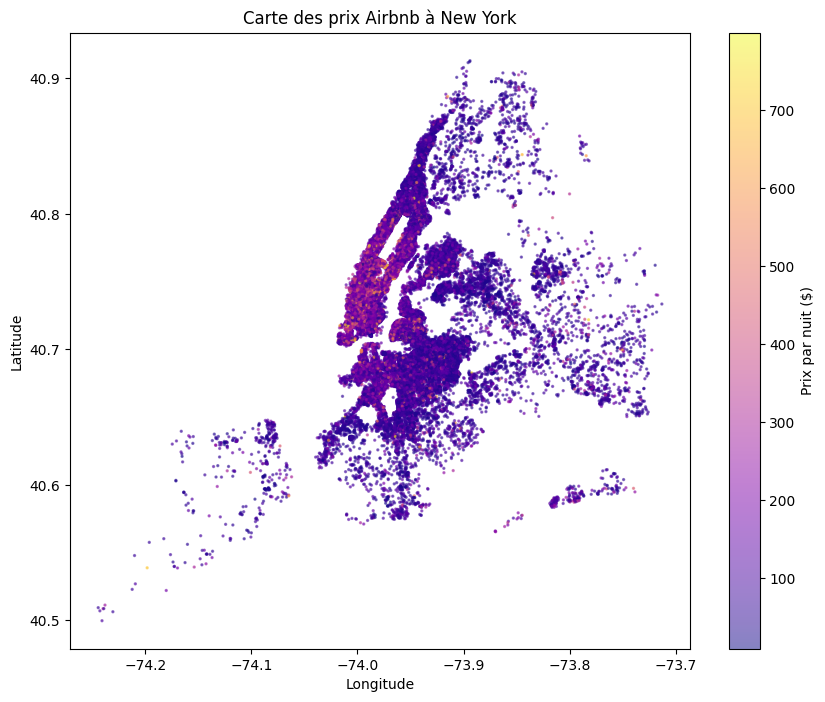

In [116]:
plt.figure(figsize=(10, 8))
plt.scatter(df_clean["longitude"], df_clean["latitude"], c=df_clean["price"], cmap="plasma", s=2, alpha=0.5)
plt.colorbar(label="Prix par nuit ($)")
plt.title("Carte des prix Airbnb à New York")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.show()

**Lecture :** les logements les plus chers (points clairs) se concentrent à **Manhattan**, surtout au sud et au centre. Plus on s'éloigne vers le Queens, le Bronx et Staten Island, plus les points sont foncés, donc moins chers. La localisation a un impact fort sur le prix.

### Prix et revenu estimé par arrondissement
On compare le prix median et le revenu estimé median des 5 arrondissements. On utilise la médiane car elle n'est pas influencée par les valeurs extrêmes. 

                     price  revenu_estime
neighbourhood_group                      
Bronx                 65.0          53.72
Brooklyn              90.0          37.20
Manhattan            149.0          39.60
Queens                75.0          55.65
Staten Island         75.0          70.59


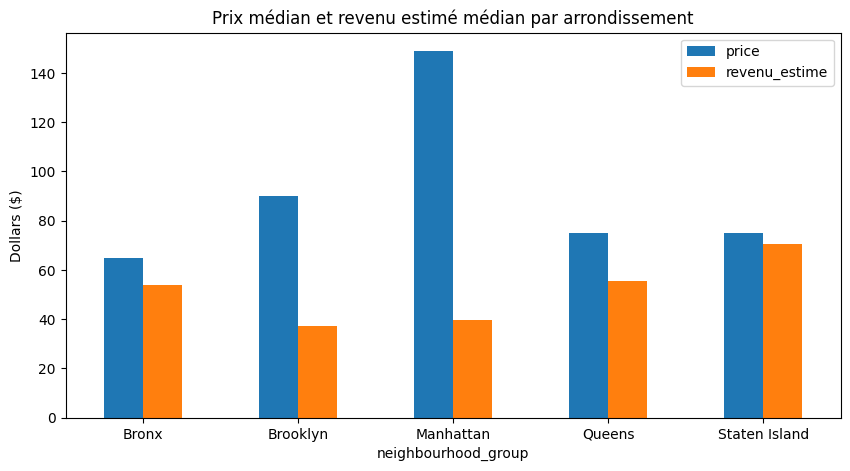

In [117]:
par_quartier = df_clean.groupby("neighbourhood_group")[["price", "revenu_estime"]].median()
print(par_quartier)

par_quartier.plot(kind="bar", figsize=(10, 5))
plt.title("Prix médian et revenu estimé médian par arrondissement")
plt.ylabel("Dollars ($)")
plt.xticks(rotation=0)
plt.show()

**Lecture :** Manhattan a le prix médian le plus élevé (149 $) mais l'un des revenus estimés les plus faibles (39,60 $). À l'inverse, le Queens (55,65 $), le Bronx (53,72 $) et Staten Island (70,59 $) sont moins chers mais plus rentables : leurs logements reçoivent plus d'avis par mois, donc ils sont loués plus souvent.

⚠️ Staten Island ne compte que 365 annonces, contre 5 598 pour le Queens. Son résultat est donc moins fiable.

### Prix selon le type de logement
On compare le prix médian par nuit des 3 types de logement.

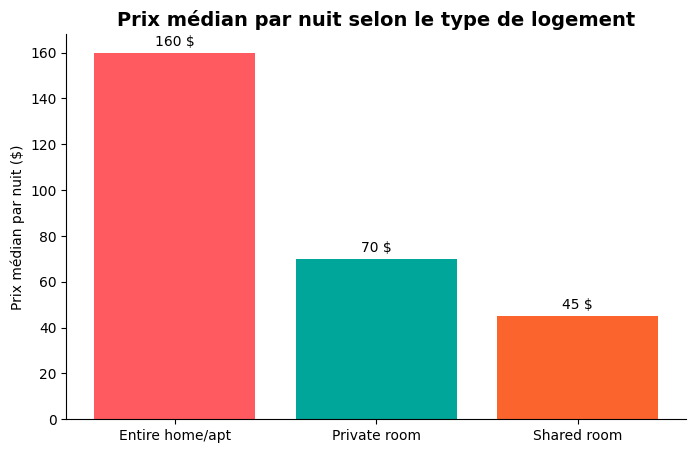

,count,median
room_type,,
Entire home/apt,24534,160.0
Private room,22024,70.0
Shared room,1134,45.0


In [118]:
prix_type = df_clean.groupby("room_type")["price"].median().sort_values(ascending=False)

plt.figure(figsize=(8, 5))
barres = plt.bar(prix_type.index, prix_type.values, color=["#FF5A5F", "#00A699", "#FC642D"])
plt.bar_label(barres, fmt="%.0f $", padding=3)
plt.title("Prix médian par nuit selon le type de logement", fontsize=14, fontweight="bold")
plt.ylabel("Prix médian par nuit ($)")
sns.despine()
plt.show()

df_clean.groupby("room_type")["price"].agg(["count", "median"])

**Lecture :** un logement entier coûte en médiane 160$ la nuit, soit plus du double d'une chambre privée (70$). Les chambres partagées sont rares (1 134 annonces) et peu chères (45$).

## 5. Première recommandation

Pour un fonds d'investissement, **le quartier le plus cher n'est pas le plus rentable**.

| Logement entier | Revenu estimé médian |
|---|---|
| Staten Island | 157,10 $ |
| Bronx | 138,70 $ |
| **Queens** | **106,60 $** |
| Brooklyn | 68,90 $ |
| Manhattan | 43,40 $ |

**Recommandation :** cibler des **logements entiers dans le Queens**. C'est le meilleur compromis entre rentabilité (un revenu estimé 2,5 fois supérieur à Manhattan) et fiabilité (5 598 annonces, un marché solide). Le Bronx et Staten Island sont prometteurs mais reposent sur trop peu d'annonces pour être sûrs.

**Limite :** le revenu estimé est un proxy basé sur les avis, pas un revenu réel.

## 6. Sauvegarde
On enregistre les données nettoyées pour les utiliser dans le notebook de modélisation.

In [119]:
df_clean.to_csv("../data/AB_NYC_2019_clean.csv", index=False)
print("Fichier sauvegardé :", df_clean.shape)

Fichier sauvegardé : (47692, 18)
